# Telco Customer Churn
**Residency Day 3 · Project Deliverable 4 · Final Insights, Recommendations, and Presentation**  
MSCS-634-M50 · Advanced Big Data and Data Mining  
Group project · Federico Poi and Umama Azhar

We use the [IBM Telco Customer Churn sample](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv) to estimate monthly bills, predict churn, group similar customers, and identify account patterns associated with churn. The source contains 7,043 customer records and 21 columns. We load and clean it once and reuse the prepared table throughout.

## 1. Setup and data preparation

In [1]:
# Install mlxtend only when it is missing, such as in a fresh notebook runtime.
from importlib.util import find_spec
import subprocess
import sys

if find_spec("mlxtend") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "mlxtend>=0.23.4,<0.26"])

In [2]:
# Import the tools used throughout this notebook.
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, f1_score,
    mean_squared_error, precision_score, r2_score, recall_score, roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import (
    GridSearchCV, KFold, StratifiedKFold, cross_val_score, cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")

# Read the public source once and inspect the raw columns before cleaning.
source_url = (
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)
raw = pd.read_csv(source_url)

# Check the dataset size, sample records, and column types before cleaning.
print(f"Raw data: {raw.shape[0]:,} rows and {raw.shape[1]} columns")
display(raw.head())
raw.info()
# Count recognized missing values and check the balance of the churn label.
display(raw.isna().sum().rename("Raw nulls").to_frame())
display(raw["Churn"].value_counts().rename("Customers").to_frame())

Raw data: 7,043 rows and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,Raw nulls
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


,Customers
Churn,
No,5174
Yes,1869


### Missing values, duplicate rows, and numeric checks

In [3]:
# Clean a copy so the original data is available for comparison.
df = raw.copy()
# Trim billing text so entries containing only spaces can be counted as blanks.
total_text = df["TotalCharges"].astype("string").str.strip()
blank_totals = total_text.eq("").fillna(False)
# Convert billing totals to numbers. Leave blanks missing because their billed amount is unknown.
df["TotalCharges"] = pd.to_numeric(total_text, errors="coerce")

# Check whether any nonblank text also failed to convert.
unexpected = total_text.notna() & ~blank_totals & df["TotalCharges"].isna()
print("Whitespace-only totals:", blank_totals.sum())
print("Unexpected nonnumeric totals:", unexpected.sum())
# See whether missing billing totals are concentrated at a particular tenure.
print("Customers with missing totals by tenure:")
display(df.loc[df["TotalCharges"].isna(), "tenure"].value_counts().to_frame("Customers"))
# List columns that still have missing values after conversion.
display(df.isna().sum().loc[lambda counts: counts.gt(0)].to_frame("Missing after conversion"))

Whitespace-only totals: 11
Unexpected nonnumeric totals: 0
Customers with missing totals by tenure:


,Customers
tenure,
0,11


,Missing after conversion
TotalCharges,11


In [4]:
# Trim extra spaces so they do not affect label or duplicate checks.
for column in df.select_dtypes(include=["object", "string"]).columns:
    df[column] = df[column].str.strip()

# Count and remove rows that are identical across every column.
duplicate_rows = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
# Check whether any customer ID still appears more than once.
repeated_ids = df["customerID"].duplicated(keep=False)
print("Exact duplicate rows removed:", duplicate_rows)
print("Rows with a repeated customer ID:", repeated_ids.sum())
print("Missing customer IDs:", df["customerID"].isna().sum())
# Review distinct category labels for inconsistent spelling or formatting.
for column in ["Churn", "Contract", "InternetService", "MultipleLines"]:
    print(f"{column}: {sorted(df[column].dropna().unique())}")

# Use recorded totals in cumulative-charge plots and keep all customers in the main table.
billing_df = df.dropna(subset=["TotalCharges"]).copy()
print(f"Customers retained: {len(df):,}")
print(f"Customers with observed total charges: {len(billing_df):,}")

Exact duplicate rows removed: 0
Rows with a repeated customer ID: 0
Missing customer IDs: 0
Churn: ['No', 'Yes']
Contract: ['Month-to-month', 'One year', 'Two year']
InternetService: ['DSL', 'Fiber optic', 'No']
MultipleLines: ['No', 'No phone service', 'Yes']
Customers retained: 7,043
Customers with observed total charges: 7,032


In [5]:
# Review numeric ranges and count negative values in tenure and billing.
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
display(df[numeric_columns].describe().round(2))
display(df[numeric_columns].lt(0).sum().rename("Negative values").to_frame())

monthly = df["MonthlyCharges"]
# Compute the quartiles and IQR to measure the spread of the middle half of monthly bills.
q1, q3 = monthly.quantile([0.25, 0.75])
iqr = q3 - q1
# Flag charges beyond 1.5 times the IQR from either quartile for review.
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
overall_flags = monthly.lt(lower) | monthly.gt(upper)
print(f"Overall IQR fences: {lower:.2f} to {upper:.2f}")
print("Monthly charges outside the overall fences:", overall_flags.sum())

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.0
mean,32.37,64.76,2283.3
std,24.56,30.09,2266.77
min,0.00,18.25,18.8
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.8


,Negative values
tenure,0
MonthlyCharges,0
TotalCharges,0


Overall IQR fences: -46.02 to 171.38
Monthly charges outside the overall fences: 0


The 11 missing totals belong to customers with zero months of tenure. We kept those customers and left their totals missing. We found no duplicate customer records or negative tenure or charge values. The overall IQR check flagged no monthly bills. We review the service-specific flags with the billing plot below.

## 2. Exploratory data analysis

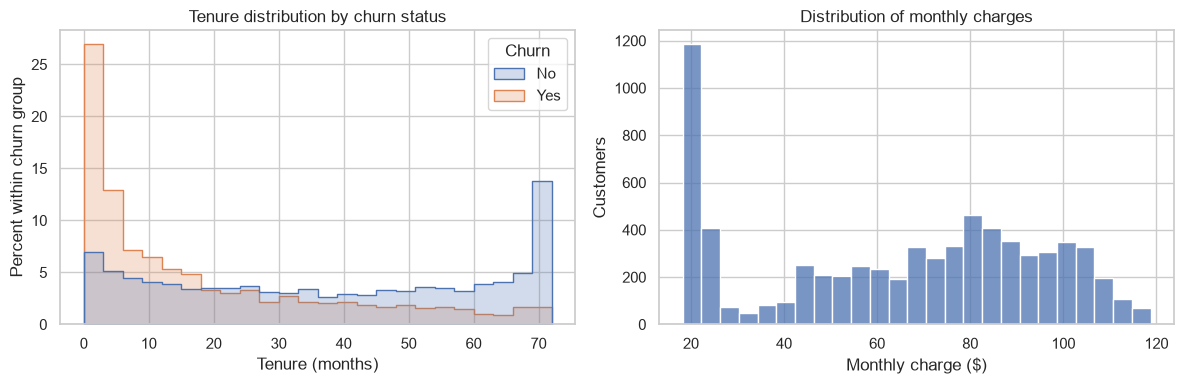

In [6]:
# Place the tenure and monthly charge distributions side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Calculate percentages separately for each churn group so their shapes are comparable.
sns.histplot(data=df, x="tenure", hue="Churn", bins=24, stat="percent",
             common_norm=False, element="step", ax=axes[0])
axes[0].set(title="Tenure distribution by churn status", xlabel="Tenure (months)",
            ylabel="Percent within churn group")
# Count customers in each billing range to show where monthly charges concentrate.
sns.histplot(data=df, x="MonthlyCharges", bins=25, ax=axes[1])
axes[1].set(title="Distribution of monthly charges", xlabel="Monthly charge ($)",
            ylabel="Customers")
plt.tight_layout()
plt.show()

About 27% of customers who churned fell in the shortest tenure bin, compared with about 7% of customers who stayed. Each percentage uses its own churn group as the denominator. This made tenure a reasonable candidate for churn classification.

Monthly bills show a sharp peak near 20 dollars and a broader concentration between 65 and 105 dollars. We compared bills by internet service to see how those price ranges line up with the services customers have.

### Monthly charges by internet service

/private/tmp/mscs634-final-notebook/deps/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


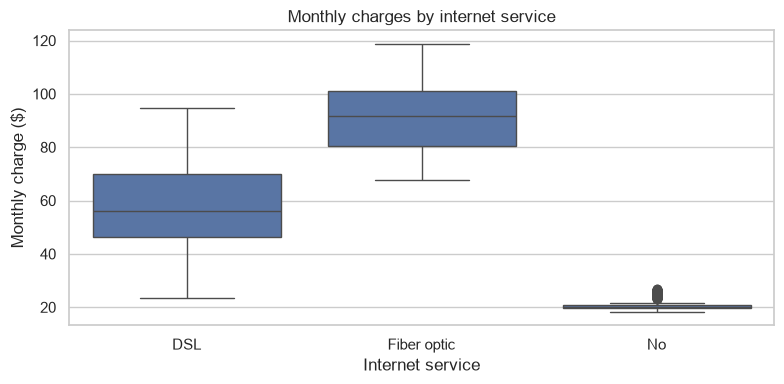

,customers,median,lowest,highest
InternetService,,,,
DSL,2421,56.150,23.45,94.80
Fiber optic,3096,91.675,67.75,118.75
No,1526,20.150,18.25,26.90


Flagged customers in the no-internet group: 342


,,customers,lowest,highest
PhoneService,MultipleLines,,,
Yes,Yes,342,22.95,26.9


In [7]:
# Compare the median, spread, and potential outliers in each internet service group.
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="InternetService", y="MonthlyCharges", ax=ax)
ax.set(title="Monthly charges by internet service", xlabel="Internet service",
       ylabel="Monthly charge ($)")
plt.tight_layout()
plt.show()

# Print the group sizes and charge summaries alongside the plot.
display(df.groupby("InternetService")["MonthlyCharges"]
          .agg(customers="size", median="median", lowest="min", highest="max"))

# Check whether the flagged bills share the same phone service setup.
no_internet = df.loc[df["InternetService"].eq("No")]
charges = no_internet["MonthlyCharges"]
# Calculate IQR fences within the no-internet group, which has its own billing range.
group_q1, group_q3 = charges.quantile([0.25, 0.75])
group_iqr = group_q3 - group_q1
flagged = no_internet.loc[
    charges.lt(group_q1 - 1.5 * group_iqr) | charges.gt(group_q3 + 1.5 * group_iqr)
]
print("Flagged customers in the no-internet group:", len(flagged))
# Summarize the flagged bills by phone service and multiple-line status.
display(flagged.groupby(["PhoneService", "MultipleLines"])["MonthlyCharges"]
               .agg(customers="size", lowest="min", highest="max"))

The median monthly bill was about 92 dollars for fiber optic customers, 56 dollars for DSL customers, and 20 dollars for customers without internet. The IQR rule flagged 342 customers within the no-internet group. Every one had phone service with multiple lines, and their bills ranged from 22.95 to 26.90 dollars. That shared service setup offers a plausible explanation for the higher bills, so we kept all 342 records. Those service attributes were included in the billing comparison.

### Total charges and tenure

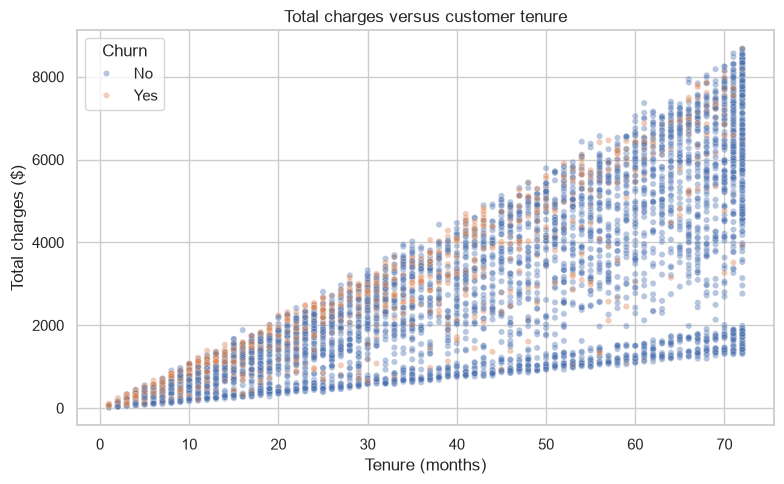

In [8]:
# Plot reported cumulative charges against tenure to examine how charges build over time.
fig, ax = plt.subplots(figsize=(8, 5))
# Color points by churn status and use transparency so overlapping customers are visible.
sns.scatterplot(data=billing_df, x="tenure", y="TotalCharges", hue="Churn",
                alpha=0.4, s=20, ax=ax)
ax.set(title="Total charges versus customer tenure", xlabel="Tenure (months)",
       ylabel="Total charges ($)")
plt.tight_layout()
plt.show()

Cumulative charges generally rose with tenure, and the spread widened for customers who had been with the company longer. We used the recorded totals for this plot and excluded cumulative charges from both supervised models.

,customers,churned,churn_pct
Contract,,,
Month-to-month,3875,1655,42.7
One year,1473,166,11.3
Two year,1695,48,2.8


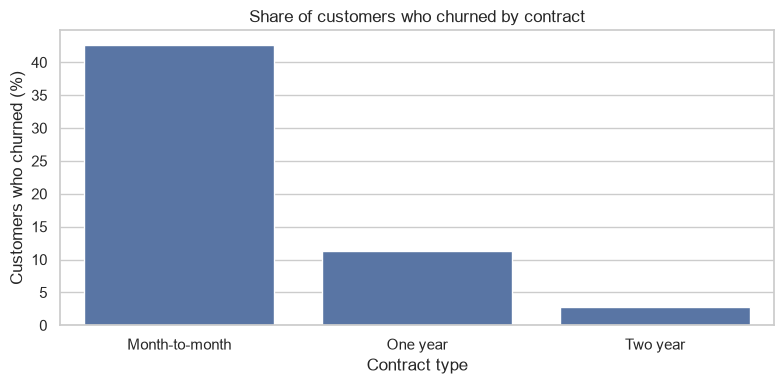

In [9]:
# Use the share who churned within each contract group so group size does not drive the comparison.
contract_summary = (
    df.assign(churned=df["Churn"].eq("Yes"))
      .groupby("Contract")["churned"]
      .agg(customers="size", churned="sum", churn_rate="mean")
      .sort_values("churn_rate", ascending=False)
)
# Convert each within-contract rate to a percentage and show its underlying counts.
contract_summary["churn_pct"] = 100 * contract_summary["churn_rate"]
display(contract_summary[["customers", "churned", "churn_pct"]].round(1))

# Plot the precomputed percentages so contract groups can be compared directly.
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=contract_summary.reset_index(), x="Contract", y="churn_pct", ax=ax)
ax.set(title="Share of customers who churned by contract", xlabel="Contract type",
       ylabel="Customers who churned (%)")
plt.tight_layout()
plt.show()

Month-to-month contracts had 42.7% observed churn, compared with 11.3% for one-year contracts and 2.8% for two-year contracts. Those rates suggest that contract type belongs in the churn analysis.

## 3. Feature engineering and monthly charge regression

The regression target is `MonthlyCharges`. We leave out the customer ID, the churn outcome, and cumulative charges. Past bills could indirectly reveal part of the monthly amount. We use the same five validation folds for every feature set and reserve a separate test set.

In [10]:
# Reset the plot style for the model evaluation figures.
plt.style.use("default")

# Set aside the target and remove fields excluded from the model.
y = df["MonthlyCharges"]
X_baseline = df.drop(columns=[
    "MonthlyCharges", "customerID", "TotalCharges", "Churn"
])

# Confirm that the retained modeling columns have no missing values.
assert not y.isna().any()
assert not X_baseline.isna().any().any()
print(f"{len(y):,} customers retained for regression")
print(f"{X_baseline.shape[1]} original predictors")

7,043 customers retained for regression
17 original predictors


### Engineer features and define the comparison

- **InternetAddonCount** counts how many of the six internet add-ons each customer uses. The original add-on columns already contain this information. We wanted to see whether summarizing it helped Ridge.
- **FiberAddonCount** uses the add-on count for fiber optic customers and zero for everyone else. This lets either linear model estimate a different bill change for each additional add-on for fiber customers.

We also test a smaller set of nine service columns. Those are internet service, phone service, multiple lines, online security, online backup, device protection, tech support, streaming TV, and streaming movies.

In [11]:
# Only "Yes" counts as a subscription. "No" and "No internet service" add zero.
addon_columns = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
addon_count = X_baseline[addon_columns].eq("Yes").sum(axis=1)
assert addon_count.between(0, len(addon_columns)).all()

# Keep the count-only version to measure what each added feature contributes.
X_count_only = X_baseline.assign(InternetAddonCount=addon_count)

# The interaction is zero for customers without fiber optic service.
is_fiber = X_baseline["InternetService"].eq("Fiber optic")
X_engineered = X_count_only.assign(FiberAddonCount=addon_count * is_fiber)

# Keep only columns that describe the services on the customer's account.
service_columns = ["InternetService", "PhoneService", "MultipleLines"] + addon_columns
X_services = X_baseline[service_columns]

print("Original features:", X_baseline.shape[1])
print("Engineered features added:", X_engineered.shape[1] - X_baseline.shape[1])
print("Total features:", X_engineered.shape[1])
print("Services-only features:", X_services.shape[1])
display(X_engineered[["InternetService", "InternetAddonCount", "FiberAddonCount"]].head())

Original features: 17
Engineered features added: 2
Total features: 19
Services-only features: 9


,InternetService,InternetAddonCount,FiberAddonCount
0,DSL,1,0
1,DSL,2,0
2,DSL,2,0
3,DSL,3,0
4,Fiber optic,0,0


### Split the data and build the models

We set aside 20% of customers for testing, then compare models with five-fold cross-validation on the remaining 80%. Every configuration uses the same customers in each fold. We fit the encoder and scaler inside each model pipeline so they learn only from the training rows of that fold.

Both models use multiple predictors. Ridge adds a penalty that shrinks coefficients. We use a fixed Ridge penalty of `alpha=1.0` for this comparison.

In [12]:
# Split the row indices once so all feature sets and targets stay aligned.
train_index, test_index = train_test_split(df.index, test_size=0.20, random_state=42)
y_train = y.loc[train_index]
y_test = y.loc[test_index]
feature_sets = {
    "Original (17)": X_baseline,
    "Add-on count (18)": X_count_only,
    "Both new features (19)": X_engineered,
    "Services only (9)": X_services,
}

# Freeze fold positions so both regressors see the same validation customers.
folds = KFold(n_splits=5, shuffle=True, random_state=42)
cv_splits = list(folds.split(y_train))
print(f"{len(y_train):,} training customers and {len(y_test):,} test customers")


def build_model(regressor):
    # Scale numeric inputs for Ridge and turn service categories into indicators.
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), make_column_selector(dtype_include="number")),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         make_column_selector(dtype_exclude="number")),
    ])
    return make_pipeline(preprocessing, regressor)


# Each call creates a fresh regressor for fitting.
model_builders = {
    "Multiple Linear Regression": LinearRegression,
    "Ridge": lambda: Ridge(alpha=1.0),
}

5,634 training customers and 1,409 test customers


### Compare cross-validation scores

We use mean RMSE to rank the configurations because it expresses error in dollars and gives larger misses more weight. MSE reports the squared error in dollars squared. R² measures how much squared error the model reduces relative to predicting the mean of the evaluation targets. We also report the standard deviation of RMSE across the five folds to show how much error varied across customer groups.

In [13]:
# Use a common set of evaluation metrics for each fold.
scoring = {
    "r2": "r2",
    "mse": "neg_mean_squared_error",
    "rmse": "neg_root_mean_squared_error",
}
cv_rows = []

for model_name, make_regressor in model_builders.items():
    for feature_name, features in feature_sets.items():
        # Cross-validation fits a fresh pipeline on four folds and scores the fifth.
        scores = cross_validate(
            build_model(make_regressor()), features.loc[train_index], y_train,
            cv=cv_splits, scoring=scoring, error_score="raise",
        )
        # Convert the negative error scores back into positive errors.
        fold_rmse = -scores["test_rmse"]
        cv_rows.append({
            "Model": model_name,
            "Features": feature_name,
            "Mean CV R²": scores["test_r2"].mean(),
            "Mean CV MSE": -scores["test_mse"].mean(),
            "Mean CV RMSE": fold_rmse.mean(),
            "CV RMSE Std": fold_rmse.std(ddof=1),
        })

# Rank on unrounded scores. Round only the displayed values.
cv_results = pd.DataFrame(cv_rows).sort_values("Mean CV RMSE").reset_index(drop=True)
display(cv_results.round(4))

,Model,Features,Mean CV R²,Mean CV MSE,Mean CV RMSE,CV RMSE Std
0,Multiple Linear Regression,Services only (9),0.9988,1.0420,1.0203,0.0369
1,Ridge,Services only (9),0.9988,1.0421,1.0203,0.0370
2,Multiple Linear Regression,Original (17),0.9988,1.0454,1.0219,0.0376
3,Multiple Linear Regression,Add-on count (18),0.9988,1.0454,1.0219,0.0376
4,Ridge,Add-on count (18),0.9988,1.0454,1.0219,0.0379
5,Ridge,Original (17),0.9988,1.0455,1.0219,0.0378
6,Multiple Linear Regression,Both new features (19),0.9988,1.0461,1.0222,0.0373
7,Ridge,Both new features (19),0.9988,1.0463,1.0223,0.0380


### Test the best configuration for each model

We select each model's feature set using cross-validation scores. Then we refit each selection on all 5,634 training customers and evaluate both models on the same 1,409 test customers.

In [14]:
# Keep the best feature set for each model based on validation RMSE.
best_per_model = cv_results.drop_duplicates(subset="Model")
test_rows = []
test_predictions = {}

for row in best_per_model.to_dict("records"):
    model_name = row["Model"]
    feature_name = row["Features"]
    features = feature_sets[feature_name]

    # Refit using all training customers and predict the held-out test set.
    model = build_model(model_builders[model_name]())
    model.fit(features.loc[train_index], y_train)
    predictions = model.predict(features.loc[test_index])
    test_predictions[model_name] = predictions

    mse = mean_squared_error(y_test, predictions)
    test_rows.append({
        "Model": model_name,
        "Features": feature_name,
        "Test R²": r2_score(y_test, predictions),
        "Test MSE": mse,
        "Test RMSE": mse ** 0.5,
    })

test_results = pd.DataFrame(test_rows)
display(test_results.round(4))

winner = cv_results.iloc[0]
print(
    f"Best by cross-validation: {winner['Model']} with {winner['Features']} "
    f"(mean RMSE: {winner['Mean CV RMSE']:.4f} dollars)"
)

,Model,Features,Test R²,Test MSE,Test RMSE
0,Multiple Linear Regression,Services only (9),0.9988,1.1034,1.0504
1,Ridge,Services only (9),0.9988,1.1038,1.0506


Best by cross-validation: Multiple Linear Regression with Services only (9) (mean RMSE: 1.0203 dollars)


### Visualize performance

The left chart compares validation RMSE across all four feature sets. Its error bars show one standard deviation across folds. The right chart compares typical prediction error on the held-out test set for the two selected models.

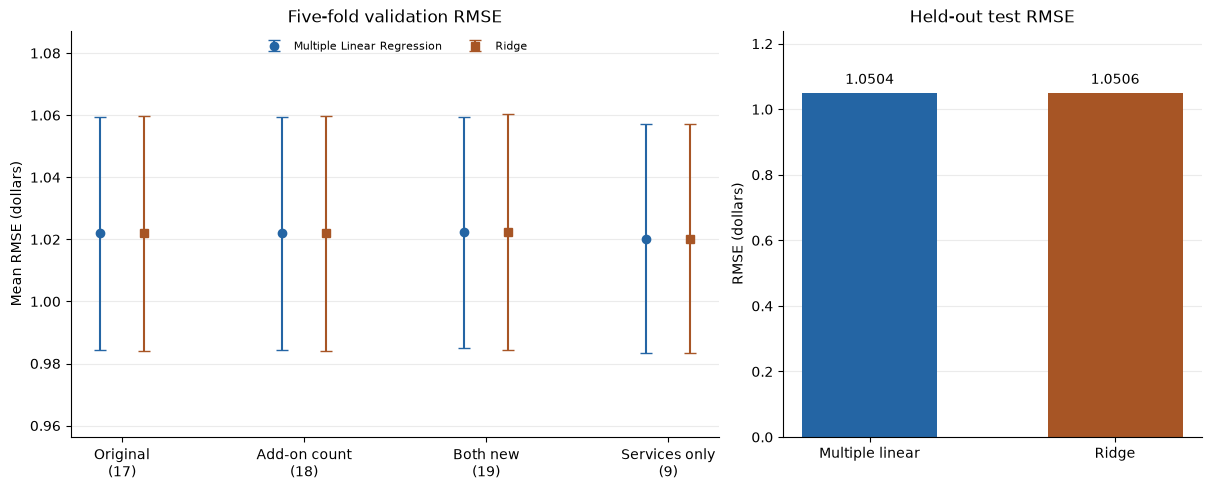

In [15]:
# Plot the two models side by side for each feature set and on the test set.
fig, (cv_ax, test_ax) = plt.subplots(
    1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.55, 1]},
    layout="constrained",
)
colors = {"Multiple Linear Regression": "#2465a4", "Ridge": "#a75525"}
markers = {"Multiple Linear Regression": "o", "Ridge": "s"}
positions = list(range(len(feature_sets)))

for model_name, offset in zip(model_builders, [-0.12, 0.12]):
    comparison = (
        cv_results[cv_results["Model"].eq(model_name)]
        .set_index("Features").loc[list(feature_sets)]
    )
    cv_ax.errorbar(
        [position + offset for position in positions], comparison["Mean CV RMSE"],
        yerr=comparison["CV RMSE Std"], fmt=markers[model_name], capsize=4,
        color=colors[model_name], label=model_name,
    )

cv_ax.set_xticks(positions, ["Original\n(17)", "Add-on count\n(18)",
                            "Both new\n(19)", "Services only\n(9)"])
cv_ax.set(title="Five-fold validation RMSE", ylabel="Mean RMSE (dollars)")
cv_ax.legend(loc="upper center", frameon=False, ncols=2, fontsize=8)
cv_ax.margins(y=0.35)

bars = test_ax.bar(
    test_results["Model"].replace({"Multiple Linear Regression": "Multiple linear"}),
    test_results["Test RMSE"],
    color=[colors[model_name] for model_name in test_results["Model"]], width=0.55,
)
test_ax.set(title="Held-out test RMSE", ylabel="RMSE (dollars)",
            ylim=(0, test_results["Test RMSE"].max() * 1.18))
test_ax.bar_label(bars, fmt="%.4f", padding=4)

for axis in (cv_ax, test_ax):
    axis.set_axisbelow(True)
    axis.grid(axis="y", alpha=0.25)
    axis.spines[["top", "right"]].set_visible(False)

plt.show()

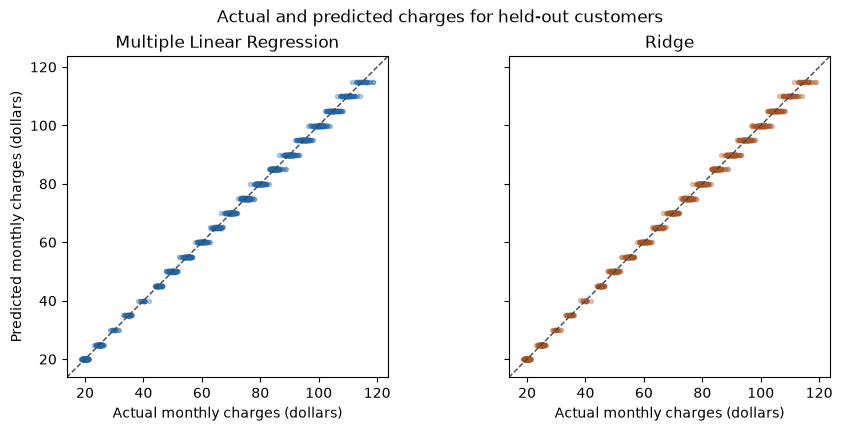

In [16]:
# Compare actual and predicted monthly charges for both selected models.
# Points near the diagonal represent accurate predictions.
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharex=True, sharey=True,
                         layout="constrained")
limits = [y_test.min() - 5, y_test.max() + 5]
for axis, (model_name, predictions) in zip(axes, test_predictions.items()):
    axis.scatter(y_test, predictions, s=9, alpha=0.3, color=colors[model_name])
    axis.plot(limits, limits, linestyle="--", color="#3e4650", linewidth=1)
    axis.set(title=model_name, xlabel="Actual monthly charges (dollars)",
             xlim=limits, ylim=limits, aspect="equal")

axes[0].set_ylabel("Predicted monthly charges (dollars)")
fig.suptitle("Actual and predicted charges for held-out customers")
plt.show()

### Regression findings

Multiple Linear Regression with nine service features had the lowest mean validation RMSE at 1.0203 dollars. Ridge with the same inputs rounded to the same score. On the held-out test set, RMSE was 1.0504 dollars for Multiple Linear Regression and 1.0506 dollars for Ridge. Both models had a test R² of 0.9988. The errors were close enough that we would choose Multiple Linear Regression for its simpler setup.

The add-on count made little difference. Adding the fiber interaction increased validation RMSE slightly for both models. The nine original service columns performed about as well as the full set of 17 predictors, so we can estimate monthly charges from the services on the customer’s account with eight fewer inputs. That makes sense for this task because the target is the bill for a known service bundle. The results describe this sample and do not establish how well the model would work under a different pricing structure.

## 4. Classify churn

We predict `Churn`, with **1** for customers who left and **0** for customers who stayed. We omit the customer ID and cumulative charges. The remaining inputs describe service, account, demographic, and monthly billing attributes. About 26.5% of customers churned, so we preserve the class proportions in the train/test split and in each fold and use F1 for customers who churned to choose the tree settings.

We compare **k-Nearest Neighbors (k-NN)** and a **Decision Tree**. For k-NN, we fix the number of neighbors at 21 and use equal votes. It predicts churn when a majority of the 21 closest training customers churned. The tree uses balanced class weights to give the minority class more weight during fitting. The pipeline fits preprocessing inside each training fold. [scikit-learn k-Nearest Neighbors](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)

In [17]:
# Make the binary target and reserve 20% of customers for the final test.
churn_target = df["Churn"].map({"No": 0, "Yes": 1})
X_churn = df.drop(columns=["Churn", "customerID", "TotalCharges"])
assert churn_target.notna().all() and not X_churn.isna().any().any()

X_churn_train, X_churn_test, y_churn_train, y_churn_test = train_test_split(
    X_churn, churn_target, test_size=0.20, stratify=churn_target, random_state=42,
)
print(f"Training customers: {len(y_churn_train):,} (churn: {y_churn_train.mean():.1%})")
print(f"Test customers: {len(y_churn_test):,} (churn: {y_churn_test.mean():.1%})")


# Reuse the preprocessing pipeline defined in the regression section.

churn_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_churn_train, y_churn_train))
# Keep k-NN fixed so the grid search tunes only the tree.
knn = build_model(KNeighborsClassifier(n_neighbors=21))
tree = build_model(DecisionTreeClassifier(class_weight="balanced", random_state=42))

Training customers: 5,634 (churn: 26.5%)
Test customers: 1,409 (churn: 26.5%)


### Tune the Decision Tree

We use grid search to try 16 combinations of two settings. `max_depth` limits the number of splits along a branch. `min_samples_leaf` sets the smallest number of training customers allowed in a final group. Smaller depth limits and larger leaves can help prevent the tree from learning quirks in the training data. We compare the selected tree against the default-depth tree and k-NN using the same five folds. [Scikit-learn GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

In [18]:
# Compare an untuned tree and k-NN using training folds only.
tree_baseline_cv = cross_val_score(tree, X_churn_train, y_churn_train, cv=churn_folds, scoring="f1")
knn_cv = cross_val_score(knn, X_churn_train, y_churn_train, cv=churn_folds, scoring="f1")

# Search tree depth and leaf size. Keep all other settings fixed.
tree_grid = {
    "decisiontreeclassifier__max_depth": [3, 5, 7, 10],
    "decisiontreeclassifier__min_samples_leaf": [10, 25, 50, 100],
}
search = GridSearchCV(tree, tree_grid, scoring="f1", cv=churn_folds, error_score="raise")
search.fit(X_churn_train, y_churn_train)

print("Best settings:", search.best_params_)
cv_comparison = pd.DataFrame({
    "Model": ["k-NN", "Decision Tree (untuned)", "Decision Tree (tuned)"],
    "Mean validation F1": [knn_cv.mean(), tree_baseline_cv.mean(), search.best_score_],
})
display(cv_comparison.round(4))

# Show the strongest candidate settings and their variation across churn_folds.
grid_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(grid_results[[
    "param_decisiontreeclassifier__max_depth",
    "param_decisiontreeclassifier__min_samples_leaf",
    "mean_test_score", "std_test_score",
]].head().round(4))

Best settings: {'decisiontreeclassifier__max_depth': 7, 'decisiontreeclassifier__min_samples_leaf': 50}


,Model,Mean validation F1
0,k-NN,0.5936
1,Decision Tree (untuned),0.4987
2,Decision Tree (tuned),0.6226


,param_decisiontreeclassifier__max_depth,param_decisiontreeclassifier__min_samples_leaf,mean_test_score,std_test_score
10,7,50,0.6226,0.0141
14,10,50,0.6207,0.0108
5,5,25,0.6201,0.0193
0,3,10,0.6194,0.0182
1,3,25,0.6194,0.0182


### Evaluate on held-out customers

Accuracy counts all correct predictions. F1 combines precision and recall for customers who churned. The confusion matrices show how often the models missed a churned customer or flagged someone who stayed. The ROC curve compares true-positive and false-positive rates across thresholds, and ROC AUC summarizes how well the model ranks churned customers above customers who stayed.

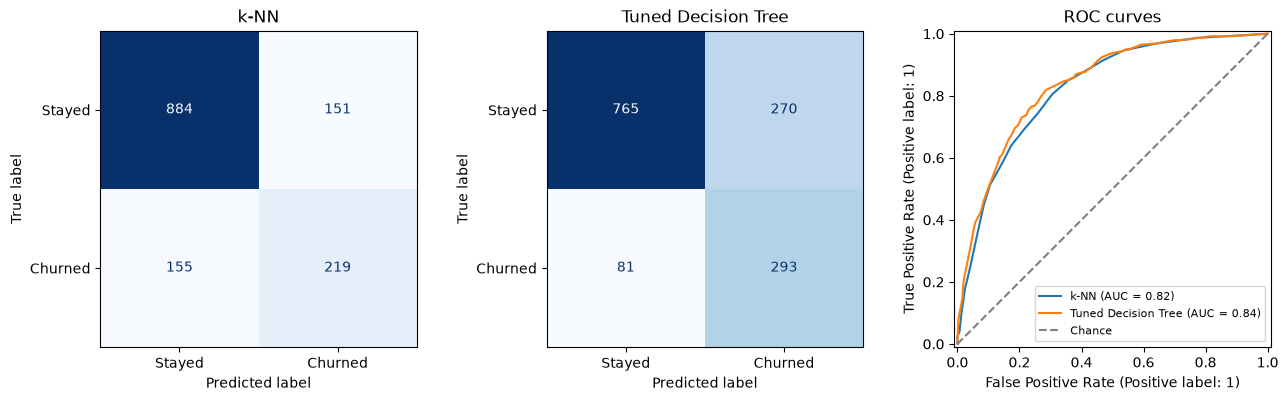

,Model,Accuracy,F1 (churn),Precision (churn),Recall (churn),ROC AUC
0,k-NN,0.7828,0.5887,0.5919,0.5856,0.824
1,Tuned Decision Tree,0.7509,0.6254,0.5204,0.7834,0.837


In [19]:
# Refit k-NN and use the tree already refit by GridSearchCV.
knn.fit(X_churn_train, y_churn_train)
classifiers = {"k-NN": knn, "Tuned Decision Tree": search.best_estimator_}
test_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), layout="constrained")

for index, (name, model) in enumerate(classifiers.items()):
    # Evaluate both models on the same customers at the default decision threshold.
    predicted = model.predict(X_churn_test)
    probability = model.predict_proba(X_churn_test)[:, 1]
    test_rows.append({
        "Model": name, "Accuracy": accuracy_score(y_churn_test, predicted),
        "F1 (churn)": f1_score(y_churn_test, predicted),
        "Precision (churn)": precision_score(y_churn_test, predicted),
        "Recall (churn)": recall_score(y_churn_test, predicted),
        "ROC AUC": roc_auc_score(y_churn_test, probability),
    })
    ConfusionMatrixDisplay.from_predictions(
        y_churn_test, predicted, display_labels=["Stayed", "Churned"],
        colorbar=False, cmap="Blues", ax=axes[index],
    )
    axes[index].set_title(name)
    RocCurveDisplay.from_predictions(y_churn_test, probability, name=name, ax=axes[2])

axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[2].set_title("ROC curves")
axes[2].legend(loc="lower right", fontsize=8)
plt.show()
classification_results = pd.DataFrame(test_rows)
display(classification_results.round(4))

The grid chose depth 7 and at least 50 customers per leaf. Tuning raised the tree's mean validation F1 from 0.4987 to 0.6226. The fixed k-NN model scored 0.5936 on the same folds.

On the held-out set, k-NN had higher accuracy (78.3% versus 75.1%). The tuned tree had higher churn F1 (0.6254 versus 0.5887), ROC AUC (0.8370 versus 0.8240), and recall (78.3% versus 58.6%). We would choose the tuned tree for retention outreach because it caught more customers who churned. It also flagged more customers who stayed, so we would check how the outreach budget changes the best threshold.

## 5. Group customers with K-Means

We cluster customers using tenure, monthly charges, contract type, and internet service. We standardize the two numeric columns and one-hot encode the two categories so dollar and month values do not dominate the distances. We fix `k=3` to keep the profiles easy to compare and report a silhouette score to describe how clearly the groups separate. We use two principal components to draw the plot. K-Means itself uses all the transformed inputs.

We leave churn out of the clustering inputs and add it back only when describing the groups. This is an exploratory view of the full dataset.

Silhouette score (2,000 sampled customers): 0.356


,Customers,MedianTenure,MedianMonthlyCharges,MonthToMonthShare,ChurnRate
Cluster,,,,,
0,1705,27.0,20.250,0.3525,0.0792
1,3006,11.0,74.400,0.9248,0.4694
2,2332,60.0,89.925,0.2118,0.1385


InternetService,DSL,Fiber optic,No
Cluster,,,
0,0.1050,0.0000,0.895
1,0.4222,0.5778,0.000
2,0.4172,0.5828,0.000


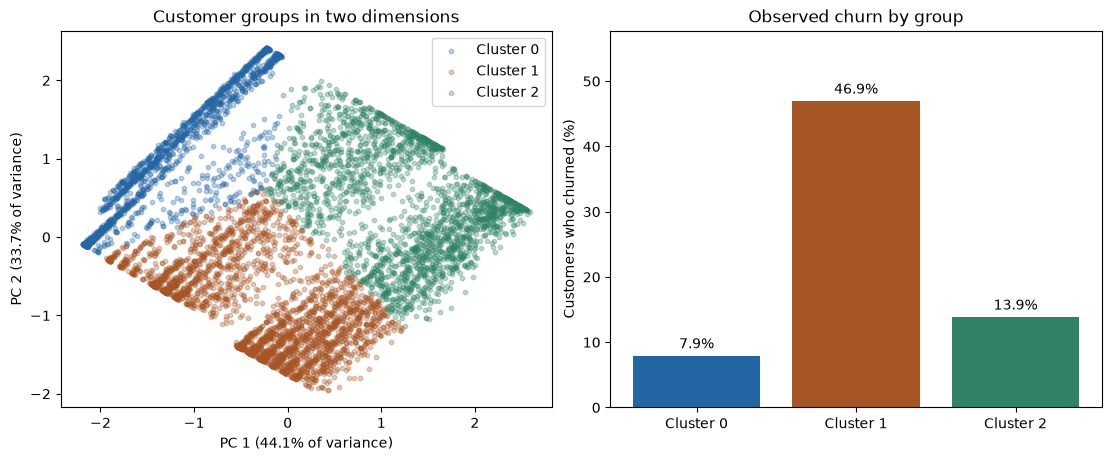

In [20]:
# Set up the unsupervised inputs and keep a copy for readable profiles.
cluster_inputs = df[["tenure", "MonthlyCharges", "Contract", "InternetService"]].copy()
cluster_preprocessing = ColumnTransformer([
    ("numeric", StandardScaler(), ["tenure", "MonthlyCharges"]),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     ["Contract", "InternetService"]),
])
cluster_matrix = cluster_preprocessing.fit_transform(cluster_inputs)

# Use multiple initializations and a fixed seed to make the groups reproducible.
cluster_model = KMeans(n_clusters=3, n_init=20, random_state=42)
cluster_ids = cluster_model.fit_predict(cluster_matrix)
silhouette = silhouette_score(cluster_matrix, cluster_ids, sample_size=2000, random_state=42)
print(f"Silhouette score (2,000 sampled customers): {silhouette:.3f}")

# Profile groups in the original units and add the observed churn rates afterward.
profile_data = cluster_inputs.assign(
    Cluster=cluster_ids, Churn=churn_target, MonthToMonth=cluster_inputs["Contract"].eq("Month-to-month"),
)
cluster_profiles = profile_data.groupby("Cluster").agg(
    Customers=("Churn", "size"),
    MedianTenure=("tenure", "median"),
    MedianMonthlyCharges=("MonthlyCharges", "median"),
    MonthToMonthShare=("MonthToMonth", "mean"),
    ChurnRate=("Churn", "mean"),
)
internet_share = pd.crosstab(
    profile_data["Cluster"], profile_data["InternetService"], normalize="index",
)
display(cluster_profiles.round(4))
display(internet_share.round(4))

# Project to two dimensions for visualization and label each group's churn rate.
pca = PCA(n_components=2)
projection = pca.fit_transform(cluster_matrix)
fig, (scatter, rate_ax) = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
cluster_colors = ["#2465a4", "#a75525", "#308365"]

for cluster, color in enumerate(cluster_colors):
    in_cluster = cluster_ids == cluster
    scatter.scatter(
        projection[in_cluster, 0], projection[in_cluster, 1],
        color=color, alpha=0.30, s=10, label=f"Cluster {cluster}",
    )

scatter.set(title="Customer groups in two dimensions",
            xlabel=f"PC 1 ({pca.explained_variance_ratio_[0]:.1%} of variance)",
            ylabel=f"PC 2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
scatter.legend()
rates = 100 * cluster_profiles["ChurnRate"]
bars = rate_ax.bar([f"Cluster {i}" for i in rates.index], rates, color=cluster_colors)
rate_ax.bar_label(bars, fmt="%.1f%%", padding=3)
rate_ax.set(title="Observed churn by group", ylabel="Customers who churned (%)",
            ylim=(0, rates.max() * 1.23))
plt.show()

| Cluster | Customers | What stands out | Observed churn |
| --- | ---: | --- | ---: |
| 0 | 1,705 | Mostly no internet service and a median monthly bill of 20.25 dollars | 7.9% |
| 1 | 3,006 | Median tenure of 11 months and about 92.5% on month-to-month contracts | 46.9% |
| 2 | 2,332 | Median tenure of 60 months and a median monthly bill of about 89.93 dollars | 13.9% |

Cluster 1 is where we would start testing a welcome check-in or a service review. Its observed churn rate was much higher than the overall rate of 26.5%. The silhouette score of 0.356 suggests some separation and some overlap, so we would use the groups to plan outreach and measure its effect before relying on the group labels.

## 6. Mine association rules with Apriori

For this analysis, each customer's account is a basket of attributes. We use contract, internet service, payment method, tech support, and churn. Apriori finds itemsets present in at least **4% of customers**, and we keep rules with **35% confidence or higher** that point to `Churn=Yes` and have **lift above 1**. We limit antecedents to two attributes for readability and remove longer rules when a shorter rule has at least the same confidence.

**Support** is the share of all customers with both sides of the rule. **Confidence** is the share with the left side who churned. **Lift** divides confidence by the overall churn rate. A lift of 2 means the observed churn rate for that group was twice the overall rate. [mlxtend Apriori and association rules](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/)

Frequent itemsets: 187; churn rules after filtering: 10


,Conditions,support,confidence,lift
107,Contract=Month-to-month + InternetService=Fiber optic,0.1650,0.5461,2.0577
133,Contract=Month-to-month + PaymentMethod=Electronic check,0.1411,0.5373,2.0247
265,InternetService=Fiber optic + PaymentMethod=Electronic check,0.1205,0.5323,2.0058
315,PaymentMethod=Electronic check + TechSupport=No,0.1306,0.5318,2.0040
152,Contract=Month-to-month + TechSupport=No,0.1917,0.5037,1.8982
275,InternetService=Fiber optic + TechSupport=No,0.1563,0.4937,1.8605


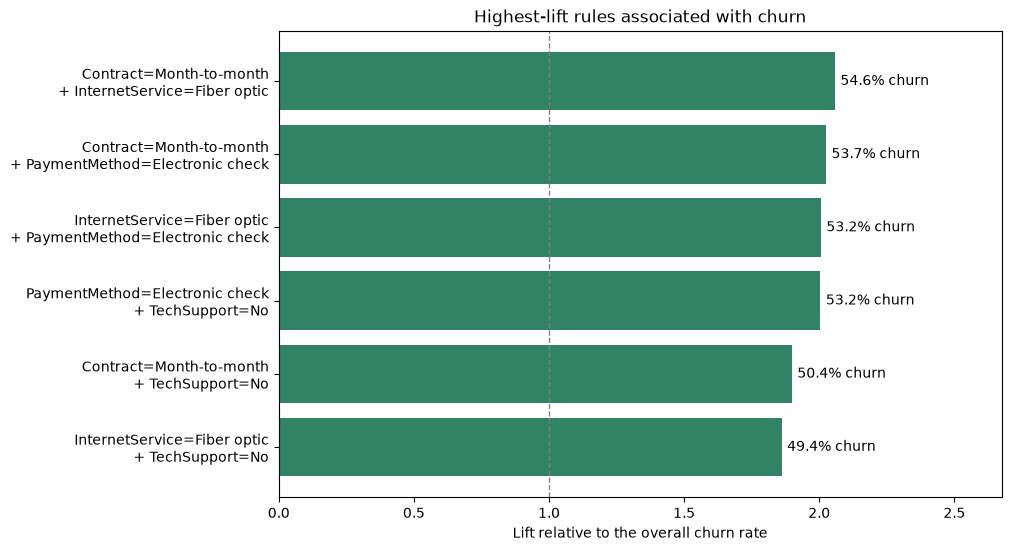

In [21]:
# Turn each account attribute into a true/false item for Apriori.
rule_columns = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "Churn"]
transactions = pd.get_dummies(df[rule_columns], prefix_sep="=", dtype=bool)
itemsets = apriori(transactions, min_support=0.04, use_colnames=True, max_len=3)
rules = association_rules(itemsets, metric="confidence", min_threshold=0.35)
target = frozenset({"Churn=Yes"})

# Keep rules pointing to churn and skip any that already use churn as an input.
candidate_rules = rules.loc[
    rules["consequents"].eq(target)
    & rules["antecedents"].map(lambda items: all(not item.startswith("Churn=") for item in items))
    & rules["lift"].gt(1)
].copy()

# Remove combinations that do no better than an available simpler rule.
confidence_by_antecedent = dict(zip(candidate_rules["antecedents"], candidate_rules["confidence"]))
keep = [
    not any(shorter < row.antecedents and confidence >= row.confidence
            for shorter, confidence in confidence_by_antecedent.items())
    for row in candidate_rules.itertuples()
]
churn_rules = candidate_rules.loc[keep].copy()
churn_rules["Conditions"] = churn_rules["antecedents"].map(lambda items: " + ".join(sorted(items)))
churn_rules = churn_rules.sort_values(["lift", "support", "Conditions"], ascending=[False, False, True])
top_rules = churn_rules.head(6)
print(f"Frequent itemsets: {len(itemsets):,}; churn rules after filtering: {len(churn_rules):,}")
with pd.option_context("display.max_colwidth", None):
    display(top_rules[["Conditions", "support", "confidence", "lift"]].round(4))

# Plot lift for a short list of highest-lift rules, with churn rates on the bars.
plot_rules = top_rules.sort_values("lift")
labels = [label.replace(" + ", "\n+ ") for label in plot_rules["Conditions"]]
fig, ax = plt.subplots(figsize=(10, 5.4), layout="constrained")
bars = ax.barh(labels, plot_rules["lift"], color="#308365")
ax.bar_label(bars, labels=[f"{value:.1%} churn" for value in plot_rules["confidence"]], padding=4)
ax.axvline(1, linestyle="--", linewidth=1, color="gray")
ax.set(title="Highest-lift rules associated with churn",
       xlabel="Lift relative to the overall churn rate",
       xlim=(0, plot_rules["lift"].max() * 1.30))
plt.show()

The highest-lift rule paired a month-to-month contract with fiber optic service. That pair and churn occurred together for 16.5% of all customers. Among customers with the pair, 54.6% churned, about 2.06 times the overall churn rate. Customers with a month-to-month contract who paid by electronic check also had a high observed churn rate (53.7%, lift 2.02).

## 7. Recommendations and ethical considerations

**Billing.** Start with the nine service fields when estimating monthly charges. Check prediction error on newer customer records after prices, discounts, or bundles change.

**Retention.** Randomly offer a service check-in to some eligible month-to-month fiber customers and compare their churn with a group that receives usual support. Track outreach effort along with churn. The tuned tree caught more churn cases at the tested cutoff, but also flagged more customers who stayed. Choose a cutoff on validation data that fits the team's capacity.

**Privacy, fairness, and limits.** We used a public sample, excluded customer IDs from predictive inputs, and described findings in groups. Stratified splits and the tree's class weights address class imbalance. Before deploying a churn model, compare false alarms and missed churn across relevant demographic groups, test models with and without demographic inputs, and restrict access to account data. This project used one customer snapshot. A later cohort and a randomized pilot would help test whether the results hold and whether the outreach actually helps.